In [2]:
import pandas as pd 
import pm4py



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




In [4]:
df=pd.read_csv("../data/demande_conge.csv")

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2855 entries, 0 to 2854
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   case_id    2855 non-null   str  
 1   activity   2855 non-null   str  
 2   timestamp  2855 non-null   str  
 3   resource   2855 non-null   str  
dtypes: str(4)
memory usage: 89.3 KB


In [7]:
df = pm4py.format_dataframe(df, case_id="case_id",
activity_key="activity", timestamp_key="timestamp")
df.head(10)

,case_id,activity,timestamp,resource,case:concept:name,concept:name,time:timestamp,@@index,@@case_index
0,C0001,Déposer la demande,2026-06-05 06:43:11+00:00,E016,C0001,Déposer la demande,2026-06-05 06:43:11+00:00,0,0
1,C0001,Valider la demande,2026-06-05 23:23:28+00:00,M3,C0001,Valider la demande,2026-06-05 23:23:28+00:00,1,0
2,C0001,Enregistrer le congé,2026-06-06 14:59:27+00:00,RH2,C0001,Enregistrer le congé,2026-06-06 14:59:27+00:00,2,0
3,C0001,Mettre à jour le planning,2026-06-06 17:58:01+00:00,RH2,C0001,Mettre à jour le planning,2026-06-06 17:58:01+00:00,3,0
4,C0001,Notifier l'employé,2026-06-06 18:45:29+00:00,Système,C0001,Notifier l'employé,2026-06-06 18:45:29+00:00,4,0
5,C0002,Déposer la demande,2026-03-18 13:03:11+00:00,E076,C0002,Déposer la demande,2026-03-18 13:03:11+00:00,5,1
6,C0002,Relancer le manager,2026-03-21 15:08:13+00:00,Système,C0002,Relancer le manager,2026-03-21 15:08:13+00:00,6,1
7,C0002,Valider la demande,2026-03-22 16:19:15+00:00,M4,C0002,Valider la demande,2026-03-22 16:19:15+00:00,7,1
8,C0002,Mettre à jour le planning,2026-03-23 01:06:20+00:00,RH2,C0002,Mettre à jour le planning,2026-03-23 01:06:20+00:00,8,1
9,C0002,Enregistrer le congé,2026-03-23 05:01:45+00:00,RH2,C0002,Enregistrer le congé,2026-03-23 05:01:45+00:00,9,1


In [12]:

variantes = pm4py.get_variants(df)
print("Nombre de variantes :", len(variantes))
for v, n in sorted(variantes.items(), key=lambda x: x[1], reverse=True)[:5]:
     print(n, " -> ".join(v))

print("Nombre de cas :", df["case:concept:name"].nunique())
print("Nombre d'événements :", len(df))
print(df["concept:name"].value_counts())

Nombre de variantes : 26
175 Déposer la demande -> Valider la demande -> Mettre à jour le planning -> Enregistrer le congé -> Notifier l'employé
144 Déposer la demande -> Valider la demande -> Enregistrer le congé -> Mettre à jour le planning -> Notifier l'employé
33 Déposer la demande -> Relancer le manager -> Valider la demande -> Mettre à jour le planning -> Enregistrer le congé -> Notifier l'employé
25 Déposer la demande -> Relancer le manager -> Valider la demande -> Enregistrer le congé -> Mettre à jour le planning -> Notifier l'employé
21 Déposer la demande -> Enregistrer le congé -> Mettre à jour le planning -> Notifier l'employé
Nombre de cas : 500
Nombre d'événements : 2855
concept:name
Valider la demande           563
Déposer la demande           500
Notifier l'employé           500
Enregistrer le congé         474
Mettre à jour le planning    474
Relancer le manager          132
Refuser la demande           110
Modifier la demande           84
Annuler la demande            

In [13]:
variantes_triees = sorted(
    variantes.items(),
    key=lambda x: x[1],
    reverse=True
)

In [14]:
for numero, (variante, nombre) in enumerate(variantes_triees[:2], start=1):
    print(f"\nVariante {numero} : {nombre} demandes")
    print(" → ".join(variante))


Variante 1 : 175 demandes
Déposer la demande → Valider la demande → Mettre à jour le planning → Enregistrer le congé → Notifier l'employé

Variante 2 : 144 demandes
Déposer la demande → Valider la demande → Enregistrer le congé → Mettre à jour le planning → Notifier l'employé


C:\Program Files\Graphviz\bin\dot.EXE


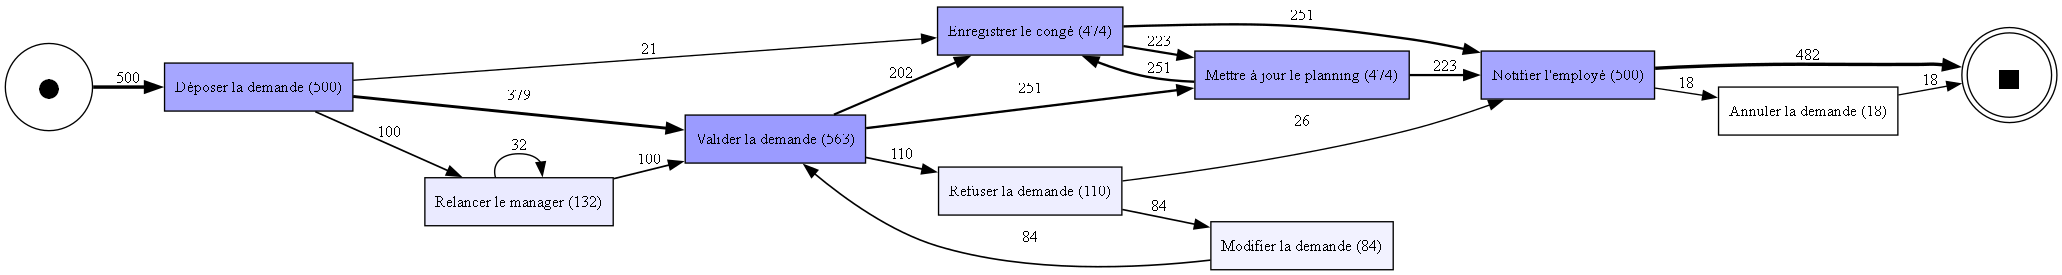

In [22]:
import os
import shutil
os.environ["PATH"] = (
    r"C:\Program Files\Graphviz\bin"
    + os.pathsep
    + os.environ["PATH"]
)

# Vérifier que Python trouve dot.exe
print(shutil.which("dot"))
dfg, debuts, fins = pm4py.discover_dfg(df)

# Afficher le graphe
pm4py.view_dfg(dfg, debuts, fins)

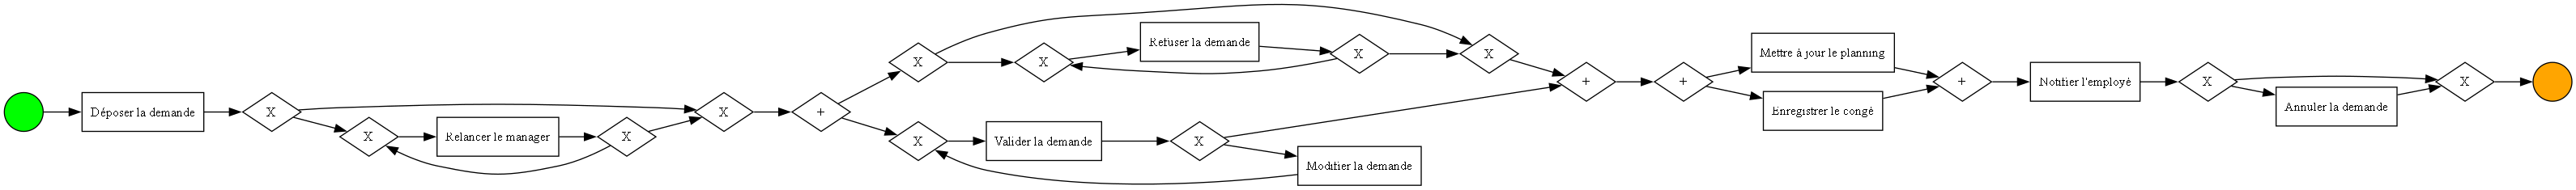

In [23]:
bpmn_filtre = pm4py.discover_bpmn_inductive(
    df,
    noise_threshold=0.2
)

pm4py.view_bpmn(bpmn_filtre)

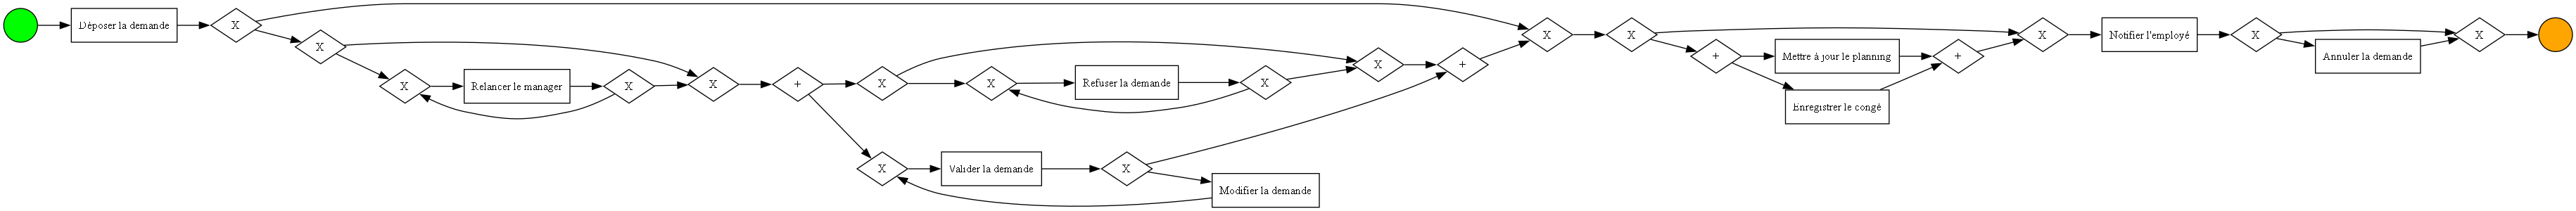

In [24]:
bpmn_complet = pm4py.discover_bpmn_inductive(
    df,
    noise_threshold=0.0
)

pm4py.view_bpmn(bpmn_complet)

#### Le premier modèle est plus simple et plus lisible. Il impose notamment la validation de la demande ainsi que l’enregistrement du congé et la mise à jour du planning avant la notification. Le deuxième modèle présente davantage de chemins de contournement : il permet notamment de sauter le bloc de validation ou le bloc d’enregistrement et de mise à jour du planning. 

#### Sans filtrage, le modèle découvert prend donc en compte davantage de comportements rares, y compris des écarts potentiels au processus prévu

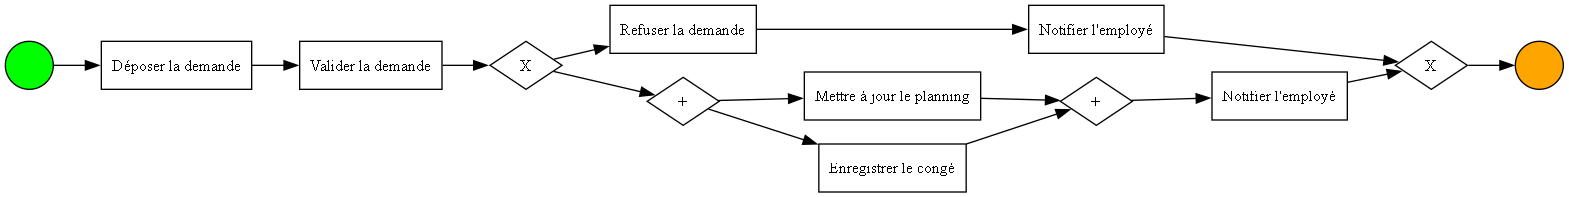

In [28]:
# Charger le modèle BPMN prévu par l'entreprise
reference = pm4py.read_bpmn("../data/modele_reference_conge.bpmn")

# Afficher le modèle de référence
pm4py.view_bpmn(reference)

# Convertir le modèle en réseau de Petri
net, im, fm = pm4py.convert_to_petri_net(reference)

# Le modèle BPMN de référence a été chargé puis converti en réseau de Petri afin de comparer les événements du journal au processus prévu par l’entreprise.

In [29]:
# Calculer la conformité du journal au modèle de référence
fitness = pm4py.fitness_alignments(df, net, im, fm)

# Calculer la précision du modèle
precision = pm4py.precision_alignments(df, net, im, fm)

# Afficher les résultats
print("Fitness du journal :", fitness["log_fitness"])
print(
    "Demandes parfaitement conformes :",
    fitness["percentage_of_fitting_traces"],
    "%"
)
print("Précision :", precision)

c:\Users\Dell\Desktop\BPMN\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
aligning log, completed variants :: 100%|██████████| 26/26 [00:00<00:00, 698.23it/s]
computing precision with alignments, completed variants :: 100%|██████████| 63/63 [00:00<00:00, 2430.83it/s]

Fitness du journal : 0.9128541621610489
Demandes parfaitement conformes : 63.8 %
Précision : 0.982782853127196


# La fitness du journal est de 0,9129, ce qui indique une bonne conformité globale au modèle de référence, sans être parfaite. Toutefois, seulement 63,8 % des demandes, soit 319 sur 500, sont parfaitement conformes. 

# Les 181 autres demandes présentent au moins un écart, dont la nature reste à identifier. Enfin, la précision de 0,9828 montre que le modèle autorise peu de comportements jamais observés. Le modèle représente donc assez fidèlement le fonctionnement observé, mais certaines pratiques s’écartent du processus prévu.

In [30]:
from collections import Counter

# Comparer chaque demande au modèle de référence
alignements = pm4py.conformance_diagnostics_alignments(
    df, net, im, fm
)

# Compter les écarts
ecarts = Counter()

for alignement in alignements:
    for dans_journal, dans_modele in alignement["alignment"]:

        # Activité présente dans le journal, mais non prévue à cet endroit
        if dans_modele == ">>":
            ecarts["En trop : " + dans_journal] += 1

        # Activité prévue par le modèle, mais absente du journal
        elif dans_journal == ">>" and dans_modele is not None:
            ecarts["Manquant : " + dans_modele] += 1

# Afficher les écarts du plus fréquent au moins fréquent
print("Écarts détectés :")

for ecart, nombre in ecarts.most_common():
    print(f"{nombre} occurrence(s) — {ecart}")

aligning log, completed variants :: 100%|██████████| 26/26 [00:00<00:00, 763.03it/s]

Écarts détectés :
132 occurrence(s) — En trop : Relancer le manager
84 occurrence(s) — En trop : Refuser la demande
84 occurrence(s) — En trop : Modifier la demande
84 occurrence(s) — En trop : Valider la demande
21 occurrence(s) — Manquant : Valider la demande
18 occurrence(s) — En trop : Annuler la demande


#### Les alignements révèlent plusieurs différences entre le journal et le modèle de référence. Les 132 relances du manager peuvent constituer un comportement acceptable, mais elles signalent un besoin de suivi. 

#### Les 84 refus, 84 modifications et 84 validations supplémentaires suggèrent une boucle de correction et de revalidation qui devrait être représentée dans le modèle si elle est autorisée. 

#### Les 18 annulations sont également à évaluer selon les règles métier.

#### Enfin, les 21 validations manquantes constituent les écarts les plus préoccupants : il faut vérifier si des congés ont été enregistrés sans l’accord du manager.

In [31]:
# 1. Garder les demandes sans aucune validation
sans_validation = pm4py.filter_event_attribute_values(
    df,
    "concept:name",
    ["Valider la demande"],
    level="case",
    retain=False
)

# 2. Parmi elles, garder celles dont le congé a été enregistré
enregistrees_sans_validation = pm4py.filter_event_attribute_values(
    sans_validation,
    "concept:name",
    ["Enregistrer le congé"],
    level="case",
    retain=True
)

# 3. Compter et afficher les demandes concernées
identifiants = enregistrees_sans_validation[
    "case:concept:name"
].unique()

print("Nombre de demandes enregistrées sans validation :", len(identifiants))
print("Les 10 premiers identifiants :", identifiants[:10])

Nombre de demandes enregistrées sans validation : 21
Les 10 premiers identifiants : <StringArray>
['C0023', 'C0055', 'C0080', 'C0085', 'C0150', 'C0238', 'C0243', 'C0249',
 'C0275', 'C0305']
Length: 10, dtype: string


#### L’analyse identifie 21 demandes enregistrées sans validation du manager dans le journal, soit 4,2 % des demandes. 

#### Sous réserve que le journal soit complet, ces cas constituent un écart grave : l’enregistrement du congé a été effectué sans l’approbation requise.

#### Il faut examiner les demandes concernées et rendre la validation obligatoire avant l’enregistrement dans le processus.

In [32]:
import statistics

# Calculer les durées des demandes en secondes
durees = pm4py.get_all_case_durations(df)

# Convertir les secondes en jours
jours = [duree / 86400 for duree in durees]

# Calculer les statistiques
moyenne = statistics.mean(jours)
mediane = statistics.median(jours)
maximum = max(jours)

print("Durée moyenne :", round(moyenne, 2), "jours")
print("Durée médiane :", round(mediane, 2), "jours")
print("Durée maximale :", round(maximum, 1), "jours")

# Comparer la moyenne à l'objectif de 2 jours
if moyenne <= 2:
    print("\nL'objectif de 2 jours est respecté en moyenne.")
else:
    print("\nL'objectif de 2 jours n'est pas respecté en moyenne.")

Durée moyenne : 2.69 jours
Durée médiane : 1.81 jours
Durée maximale : 12.2 jours

L'objectif de 2 jours n'est pas respecté en moyenne.


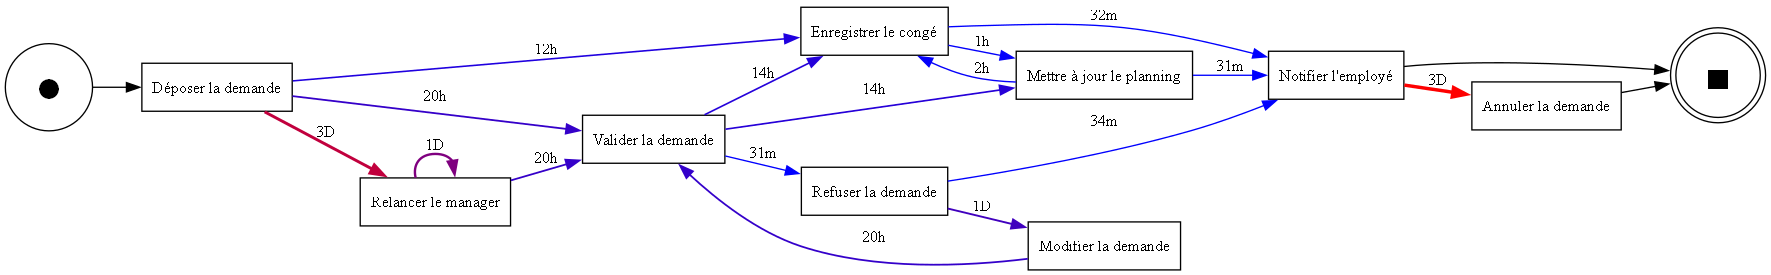

In [33]:
# Calculer les temps entre les activités
perf, debuts, fins = pm4py.discover_performance_dfg(df)

# Afficher le graphe de performance
pm4py.view_performance_dfg(perf, debuts, fins)

# L’objectif de 2 jours n’est pas respecté en moyenne : les demandes durent 2,69 jours, soit un dépassement de 0,69 jour. Cependant, la médiane est de 1,81 jour. L’écart entre la moyenne et la médiane indique que certaines demandes longues tirent la moyenne vers le haut, avec une durée maximale de 12,2 jours


# Le graphe suggère que le principal goulot du traitement se situe dans l’attente de l’intervention du manager. Pour les demandes nécessitant une relance, le délai moyen entre le dépôt et la première relance est de 3 jours. Les relances successives sont espacées en moyenne d’un jour, et la transition entre une relance et la validation dure en moyenne 20 heures.

# Le délai de 3 jours entre la notification et l’annulation est également élevé, mais il correspond à une action après notification et ne doit pas être confondu avec une attente avant validation.


In [34]:
# Trier les événements par demande et par date
d = df.sort_values(
    ["case:concept:name", "time:timestamp"]
).copy()

# Regrouper les événements par demande
g = d.groupby("case:concept:name")

# Récupérer l'activité suivante, sa date et sa ressource
d["suivante"] = g["concept:name"].shift(-1)
d["t_suivante"] = g["time:timestamp"].shift(-1)
d["manager"] = g["resource"].shift(-1)

# Garder les transitions qui arrivent à une validation
v = d[d["suivante"] == "Valider la demande"].copy()

# Calculer le temps écoulé avant validation, en heures
v["attente_h"] = (
    v["t_suivante"] - v["time:timestamp"]
).dt.total_seconds() / 3600

# Comparer les managers, du délai moyen le plus élevé au plus faible
resultats = (
    v.groupby("manager")["attente_h"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "Nombre de validations",
        "mean": "Attente moyenne (heures)"
    })
    .sort_values("Attente moyenne (heures)", ascending=False)
    .round(1)
)

display(resultats)

,Nombre de validations,Attente moyenne (heures)
manager,,
M3,93,39.5
M4,127,17.5
M5,99,16.6
M1,125,16.5
M2,119,16.3


# D.3
# Le manager M3 se distingue par un délai moyen avant validation de 39,5 heures, calculé sur 93 validations. Les autres managers présentent des délais moyens compris entre 16,3 et 17,5 heures. M3 constitue donc une piste prioritaire pour analyser les retards de validation. Il faudrait examiner sa charge de travail et sa disponibilité avant de conclure à la cause du retard. Un rappel automatique, puis une délégation ou une escalade en cas d’absence, pourraient réduire ces délais.

# Q1 — Statistiques du journal

In [35]:
print("Nombre de cas :", df["case:concept:name"].nunique())
print("Nombre d'événements :", len(df))
print("Nombre d'activités distinctes :", df["concept:name"].nunique())
print("Nombre de variantes :", len(variantes))

print("\nListe des activités :")
for activite in sorted(df["concept:name"].unique()):
    print("-", activite)

Nombre de cas : 500
Nombre d'événements : 2855
Nombre d'activités distinctes : 9
Nombre de variantes : 26

Liste des activités :
- Annuler la demande
- Déposer la demande
- Enregistrer le congé
- Mettre à jour le planning
- Modifier la demande
- Notifier l'employé
- Refuser la demande
- Relancer le manager
- Valider la demande


# Le journal contient 500 cas, … événements, … activités distinctes et … variantes. Les alignements ont notamment signalé comme activités supplémentaires « Relancer le manager », « Refuser la demande », « Modifier la demande » et « Annuler la demande ».

# Les validations supplémentaires correspondent à une activité déjà prévue dans le processus, mais exécutée à un endroit ou un nombre de fois non prévu par le modèle.

# Q3 — Conformité au modèle de référence

# La fitness du journal est de 0,9129, ce qui indique une bonne conformité globale au modèle de référence, sans être parfaite.

# 63,8 % des demandes sont parfaitement conformes, soit 319 demandes sur 500. Les 181 demandes restantes (36,2 %) présentent au moins un écart par rapport au modèle.

## Q4 — Classification des écarts et rôle de Camunda

### 1. Écarts graves

Les **21 demandes enregistrées sans validation**, soit **4,2 % des demandes**, constituent un écart grave : le congé a été enregistré sans qu’un accord du manager apparaisse dans le journal. Cette conclusion suppose que le journal est complet.

### 2. Écarts acceptables ou à vérifier

- **132 relances du manager** : elles sont acceptables, car elles permettent de rappeler une demande en attente. Elles devraient cependant être intégrées au modèle BPMN.
- **84 refus, 84 modifications et 84 validations supplémentaires** : ces événements suggèrent une boucle de correction et de revalidation. Ce comportement est acceptable si une validation intervient avant l’enregistrement du congé. L’examen des traces doit confirmer cette interprétation.
- **18 annulations** : elles sont acceptables si les règles de l’entreprise les autorisent et si elles entraînent les corrections nécessaires dans le planning et l’enregistrement du congé.

#### 3. Comment Camunda aurait-il empêché les validations sautées ?

Avec un modèle correctement conçu et exécuté par Camunda, la tâche d’enregistrement ne serait accessible qu’après la validation du manager.

Une passerelle exclusive vérifierait la décision :
- **Demande approuvée** : passage à l’enregistrement du congé et à la mise à jour du planning.
- **Demande refusée** : retour pour modification ou fin du processus.

Ainsi, l’enregistrement serait bloqué tant que l’approbation n’aurait pas été obtenue. Cette protection suppose que toutes les opérations passent par le processus, sans contournement dans une application externe.

## Q5 — Respect de l’objectif, goulot d’étranglement et amélioration du BPMN

### 1. L’objectif de 2 jours est-il respecté ?

L’objectif n’est **pas respecté en moyenne** : la durée moyenne des demandes est de **2,69 jours**, soit un dépassement de **0,69 jour**.

Cependant, la durée médiane est de **1,81 jour** : au moins la moitié des demandes sont donc traitées en moins de 2 jours. Certaines demandes très longues augmentent la moyenne, avec une durée maximale de **12,2 jours**.

### 2. Quel est le principal goulot du processus ?

Le principal goulot identifié est **l’attente avant l’intervention du manager**.

Le graphe de performance montre notamment :
- **3 jours** en moyenne entre le dépôt et la première relance, pour les demandes suivant cette transition ;
- **1 jour** entre deux relances successives ;
- **20 heures** entre une relance et la validation.

L’analyse par manager montre que **M3** présente le délai moyen avant validation le plus élevé : **39,5 heures**, contre **16,3 à 17,5 heures** pour les autres managers.

Ces résultats invitent à examiner sa charge de travail et sa disponibilité, sans attribuer automatiquement le retard à un manque d’efficacité.

**Limite :** les délais par manager mesurent le temps entre la validation et l’événement immédiatement précédent, et non le délai total depuis le dépôt.

### 3. Quelle amélioration proposer au modèle BPMN ?

Il est proposé d’ajouter un **événement de minuterie non interruptif attaché à la tâche de validation du manager** :

1. Après **24 heures sans décision**, un rappel automatique est envoyé au manager.
2. Si l’attente persiste, une escalade ou une délégation vers un responsable remplaçant est déclenchée.
3. L’enregistrement du congé reste conditionné à une approbation effective.

Cette amélioration vise à réduire les attentes tout en maintenant le contrôle obligatoire du manager. Le seuil de rappel doit être ajusté pour laisser suffisamment de temps aux étapes suivantes afin de respecter l’objectif global de 2 jours.